# 04 · Wrong-Model & Systematics Stress Tests

Shows how the diagnostics respond when the interpreter's model is wrong, and
how adding systematics freedom recovers an injected systematic. This is the
behaviour the consensus layer is meant to act on.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import mstest_utils as mu          # shared helpers (lives in metascience/python/)
import interpret, cosmology, consensus

np.random.seed(0)
plt.rcParams['figure.figsize'] = (8, 4.5)

## 1. Model-mismatch grid

Fit several candidate cosmologies to the *same* damped-driven-oscillator data.
The matched model should give χ²/dof ≈ 1; mismatched models should stand out
with large χ²/dof. (Each fit is wrapped so one failure doesn't stop the sweep.)

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 1.06309238  0.46106078 -3.56997003 -0.01934474]


Initial guess:[1.         0.5        0.2        0.3        3.14159265 0.
 1.         0.        ]


best fit:[ 9.99549122e-01  4.92970598e-01  1.05876244e+00  5.32900984e-02
  4.43481513e+00 -3.87160377e-03  1.00562881e+00  7.11698792e-03]


Initial guess:[1.         0.25       0.5        0.2        0.3        3.14159265
 0.         1.         0.        ]


best fit:[ 1.00883748  0.04268415  0.51097509  0.35882549  0.16461385  3.8216882
 -0.00571546  1.01989945  0.00817496]


interpreter model                           chi2/dof    param0    sigma0  status
CosineCosmology                                15.08     1.063    0.0088  ok
DampedDrivenOscillatorCosmology                 1.00     1.000    0.0215  ok
DampedDrivenOscillatorVariableGCosmology        1.00     1.009    0.2276  ok


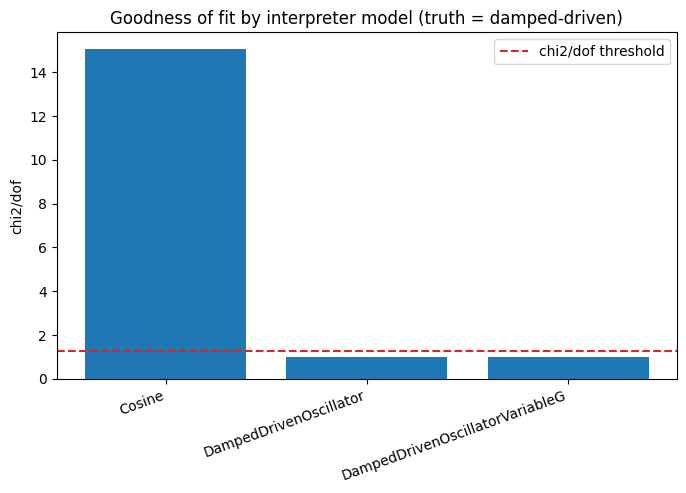

In [2]:
candidates = ['CosineCosmology', 'DampedDrivenOscillatorCosmology',
              'DampedDrivenOscillatorVariableGCosmology']
rows = []
for name in candidates:
    try:
        _, it, _ = mu.run_fit(truth_name='DampedDrivenOscillatorCosmology',
                              interp_name=name, times='times_A.txt', noise=0.03, seed=110)
        rows.append((name, mu.chi2_per_dof(it), it.best_fit_cosmological_parameters[0],
                     mu.cosmo_errors(it)[0], 'ok'))
    except Exception as e:
        rows.append((name, np.nan, np.nan, np.nan, f'{type(e).__name__}'))

print(f"{'interpreter model':42s} {'chi2/dof':>9s} {'param0':>9s} {'sigma0':>9s}  status")
for name, c, p, s, st in rows:
    print(f'{name:42s} {c:9.2f} {p:9.3f} {s:9.4f}  {st}')

ok = [(n,c) for n,c,_,_,st in rows if st=='ok' and np.isfinite(c)]
if ok:
    plt.bar([n.replace('Cosmology','') for n,_ in ok], [c for _,c in ok])
    plt.axhline(1.25, color='C3', ls='--', label='chi2/dof threshold'); plt.legend()
    plt.ylabel('chi2/dof'); plt.xticks(rotation=20, ha='right')
    plt.title('Goodness of fit by interpreter model (truth = damped-driven)');

## 2. Does adding systematics terms actually help?

The consensus layer responds to a bad fit by granting an interpreter more
systematics freedom (extra Laguerre terms). This test asks whether that
mechanism works: sweep the number of terms for a **matched** interpreter and a
**mismatched** one, fitting the same data, and watch χ²/dof.


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 1.06309238  0.46106078 -3.56997003 -0.01934474]


Initial guess:[0.5 2.  0.  0.  0. ]


best fit:[ 1.06434055  0.46140799 -3.57452631  0.33577691 -0.35549424]


Initial guess:[0.5 2.  0.  0.  0.  0. ]


best fit:[  1.06505113   0.4618512   -3.57770286  11.37913834 -22.47425384
  11.11110838]


Initial guess:[0.5 2.  0.  0.  0.  0.  0. ]


... (14 outputs left out)

best fit:[ 1.00548583e+00  4.96929171e-01  1.59568140e-01  3.53275500e-01
  2.86543644e+00 -1.12030303e-04  9.90182973e-01 -1.42718748e+00
  6.92304287e-01  1.45042577e+00  7.57654092e-01 -1.48134546e+00]


Initial guess:[1.         0.5        0.2        0.3        3.14159265 0.
 1.         0.         0.         0.         0.         0.
 0.        ]


best fit:[ 1.00286925e+00  4.98210621e-01  1.89072737e-01  3.02427109e-01
  3.12985200e+00 -2.23865945e-03  9.97721427e-01 -7.76392334e-01
  1.59694071e-01  6.26751913e-01  6.23748494e-01  1.50814758e-01
 -7.90884041e-01]


Damped-driven (matched)     : [np.float64(1.0), np.float64(1.0), np.float64(0.99), np.float64(0.99), np.float64(0.99), np.float64(0.99)]


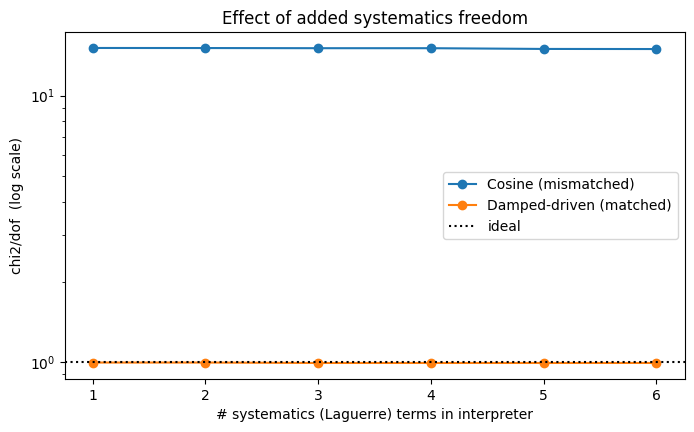

In [3]:
n_terms = [1, 2, 3, 4, 5, 6]
curves = {}
for model, label in [('CosineCosmology', 'Cosine (mismatched)'),
                     ('DampedDrivenOscillatorCosmology', 'Damped-driven (matched)')]:
    c2d = []
    for n in n_terms:
        try:
            _, it, _ = mu.run_fit(truth_name='DampedDrivenOscillatorCosmology', interp_name=model,
                                  times='times_A.txt', noise=0.03,
                                  starting_systematics=np.zeros(n), seed=110)
            c2d.append(mu.chi2_per_dof(it))
        except Exception:
            c2d.append(np.nan)
    curves[label] = c2d
    print(f'{label:28s}:', [round(x, 2) for x in c2d])

for label, c in curves.items():
    plt.plot(n_terms, c, 'o-', label=label)
plt.axhline(1.0, color='k', ls=':', label='ideal')
plt.yscale('log')
plt.xlabel('# systematics (Laguerre) terms in interpreter')
plt.ylabel('chi2/dof  (log scale)')
plt.title('Effect of added systematics freedom'); plt.legend();

### Reading this
Section 1 confirms χ²/dof is a usable model-selection signal: the matched
cosmology sits near 1 while cosine is far above threshold. Section 2 shows the
systematics basis can absorb an injected term, so χ²/dof drops toward 1 as
terms are added — the mechanism the consensus loop relies on when it decides to
"add systematic sophistication" rather than change the cosmology.